## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,RocCurveDisplay


In [2]:
X_train = pd.read_csv("../data/X_train_selected.csv")
X_test = pd.read_csv("../data/X_test_selected.csv")

y_train = pd.read_csv("../data/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/y_test.csv").squeeze("columns")

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (242, 12)
Testing shape: (61, 12)


## Classification Models

In [3]:
models = {
    "Logistic Regression": LogisticRegression( max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200,random_state=42),
    "SVM": SVC(kernel="rbf",random_state=42)
}

### Training and Testing

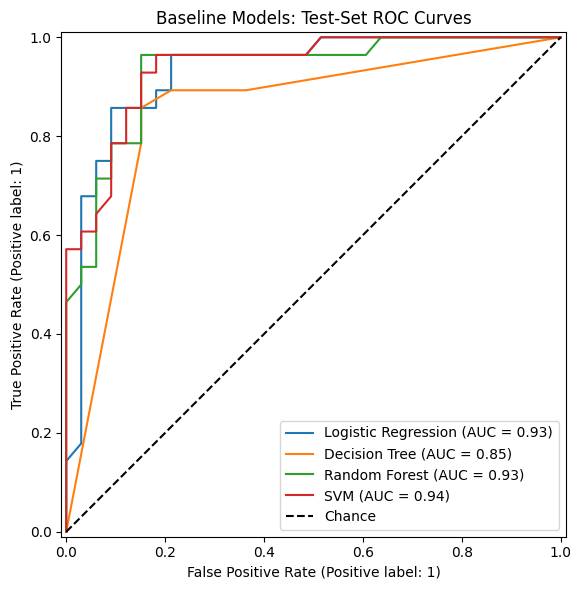

In [4]:
results = []

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Continuous scores for ROC and AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_score)
    })

    # Add the model's ROC curve
    RocCurveDisplay.from_predictions(
        y_test,
        y_score,
        name=name,
        ax=ax
    )

    # Save the classifier
    filename = name.lower().replace(" ", "_")
    joblib.dump(model, f"../models/{filename}_baseline.pkl")

ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("Baseline Models: Test-Set ROC Curves")
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("../results/baseline_classification_roc_curves.png")
plt.show()

### Performance Comparison

In [6]:
metrics_df = pd.DataFrame(results)
metrics_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.8361,0.8000,0.8571,0.8276,0.9307
1,Decision Tree,0.8525,0.8276,0.8571,0.8421,0.8501
2,Random Forest,0.8689,0.8333,0.8929,0.8621,0.9318
3,SVM,0.8689,0.8571,0.8571,0.8571,0.9405


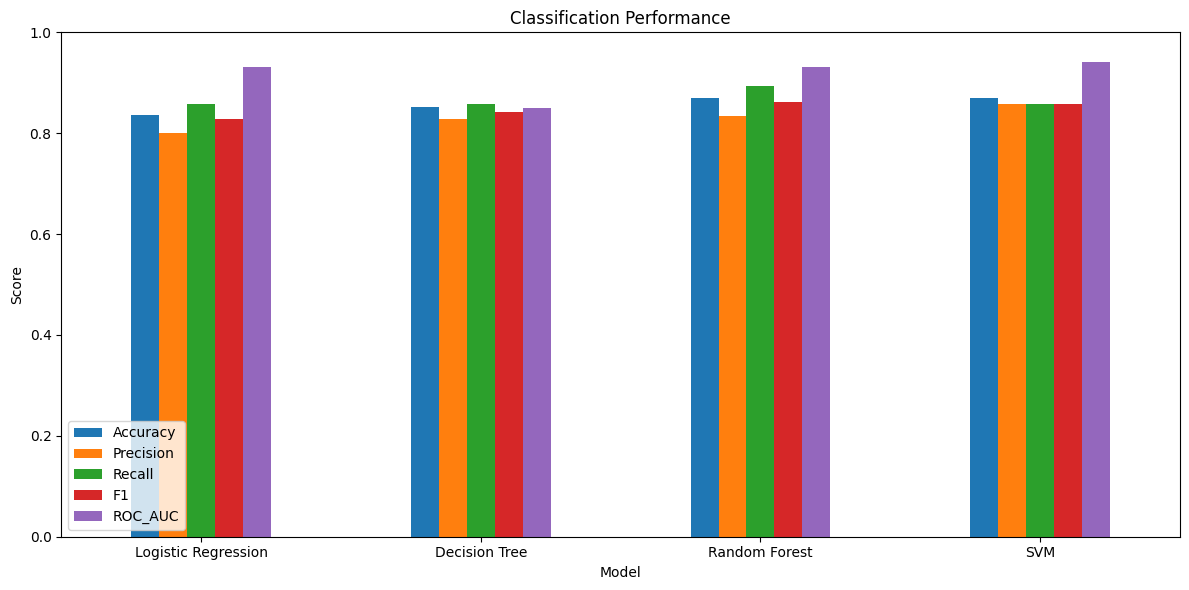

In [7]:
metrics_df.set_index("Model").plot(kind="bar",figsize=(12, 6))

plt.title("Classification Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig("../results/baseline_classification_metrics_comparison.png")
plt.show()

## Save Results

In [ ]:
metrics_df.to_csv("../results/baseline_classification_metrics.csv",index=False)

with open("../results/evaluation_metrics.txt", "w") as file:
    file.write("Baseline Classification Models\n")
    file.write("Evaluation on the held-out 20% test set\n")
    file.write("Positive class: 1 = disease present\n\n")
    file.write(metrics_df.round(4).to_string(index=False))